In [1]:
from typing import Annotated, TypedDict

from langchain_core.messages import AIMessage, BaseMessage, HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph, add_messages

In [2]:
class ChatbotState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [3]:
llm = ChatOpenAI(
    base_url='http://127.0.0.1:9931/v1',
    model='local qwen3.5:4b',
    api_key='not needed'
)

In [4]:
def chat(state: ChatbotState):
    response = AIMessage(content=llm.invoke(state['messages']).content)
    return {'messages': [response]}

In [5]:
graph = StateGraph(ChatbotState)

graph.add_node('chat', chat)

graph.add_edge(START, 'chat')
graph.add_edge('chat', END)

checkpointer = InMemorySaver()
chatbot = graph.compile(checkpointer=checkpointer)

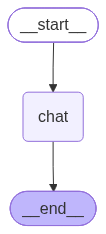

In [6]:
chatbot

In [11]:
config = {'configurable': {'thread_id': '1'}}

while True:
    user_input = input('Enter your question')
    if user_input.strip().lower() == 'exit':
        break

    print('User: ', user_input)

    response_state = chatbot.invoke({'messages': HumanMessage(content=user_input)}, config=config)

    print('Bot: ', response_state['messages'][-1].content)

User:  Hi
Bot:  Hello! How's your day going? Is there anything specific you'd like to chat about or need help with?
User:  What is your name?
Bot:  My name is **Qwen3.5**. I'm a large language model developed by Alibaba Cloud. How can I assist you?
User:  Do you remember what my last question to you was?
Bot:  Yes, I remember! Your last question was:

**"What is your name?"**

I answered that I am **Qwen3.5**, a large language model developed by Alibaba Cloud. Is there anything else you'd like to know or discuss?
User:  No have a good day
Bot:  You too! Have a wonderful day! 😊


In [13]:
list(chatbot.get_state_history(config=config))

[StateSnapshot(values={'messages': [HumanMessage(content='HI', additional_kwargs={}, response_metadata={}, id='c675d57b-9500-4110-adfb-99f745b34a23'), AIMessage(content='Hi there! How can I help you today?', additional_kwargs={}, response_metadata={}, id='5e917a60-8da6-473b-bb32-39f257aa4983', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='a925fbee-ba0b-4e25-b171-22affb039386'), AIMessage(content="Hello! How's your day going? Is there anything specific you'd like to chat about or need help with?", additional_kwargs={}, response_metadata={}, id='585cf3b9-4cbc-4410-bb60-e1ca9cb5cce8', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='What is your name?', additional_kwargs={}, response_metadata={}, id='4de3c619-aa3e-4d4f-8d4d-8c028c9edf99'), AIMessage(content="My name is **Qwen3.5**. I'm a large language model developed by Alibaba Cloud. How can I assist you?", additional_kwargs={}, response_metadata={}, id='d99